In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [4]:
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/insurance.csv')
print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000 

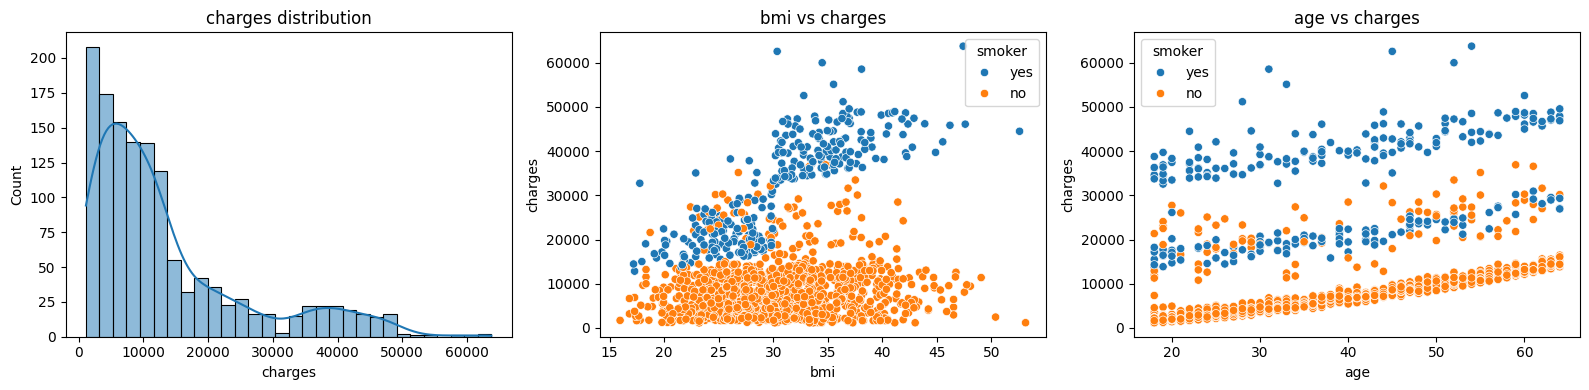

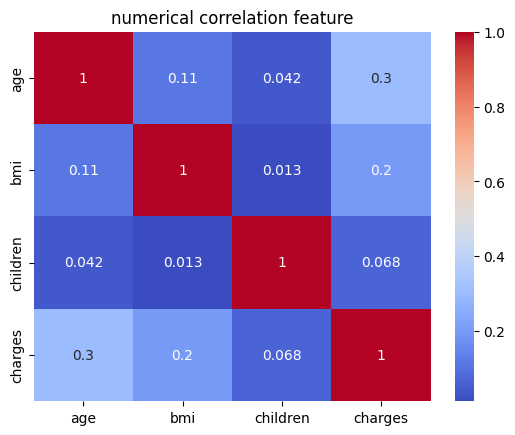

In [6]:
# visualize
fig, ax = plt.subplots(1,3,figsize=(16,4))
sns.histplot(df["charges"], kde=True, ax=ax[0]); ax[0].set_title('charges distribution')
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", ax=ax[1]); ax[1].set_title('bmi vs charges')
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", ax=ax[2]); ax[2].set_title('age vs charges')
plt.tight_layout()
plt.show()

sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm")
plt.title("numerical correlation feature")
plt.show()

In [7]:
# feature n target
X = df.drop(columns="charges")
y = df["charges"]

num_cols = ["age", "bmi", "children"]
cat_cols = ["sex", "smoker", "region"]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(1070, 6) (268, 6)


In [9]:
# preprocessing
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first"), cat_cols)
])

In [10]:
# linear regression
lin_model = Pipeline([
    ("prep", preprocess),
    ("reg", LinearRegression()),
])

lin_model.fit(X_train, y_train)
y_pred_lin = lin_model.predict(X_test)

{'model': 'linear regression', 'r2': 0.7835929767120723, 'mse': 33596915.85136146, 'rmse': np.float64(5796.2846592762735), 'mae': 4181.194473753649}


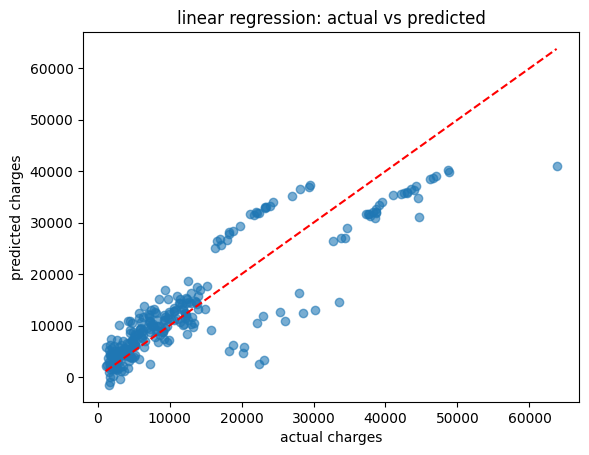

In [12]:
def eval(name, y_true, y_pred):
  mse = mean_squared_error(y_true, y_pred)
  return {
      "model": name,
      "r2": r2_score(y_true, y_pred),
      "mse": mse,
      "rmse": np.sqrt(mse),
      "mae": mean_absolute_error(y_true,y_pred)
  }

res_lin = eval("linear regression", y_test, y_pred_lin)
print(res_lin)

plt.scatter(y_test, y_pred_lin, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("actual charges"); plt.ylabel("predicted charges")
plt.title("linear regression: actual vs predicted")
plt.show()

In [15]:
# SVR
def make_svr(**kw):
  return TransformedTargetRegressor(
      regressor=Pipeline([("prep", preprocess), ("svr", SVR(**kw))]),
      transformer=StandardScaler(),
  )

svr_base = make_svr()
svr_base.fit(X_train, y_train)
res_svr_base = eval("svr default", y_test, svr_base.predict(X_test))

param_grid = {
    "regressor__svr__kernel": ["rbf", "linear"],
    "regressor__svr__C": [0.1, 1, 10, 100],
    "regressor__svr__epsilon": [0.01, 0.1, 0.2],
    "regressor__svr__gamma": ["scale", 0.01, 0.1]
}

grid = GridSearchCV(make_svr(), param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

print("best param: ", grid.best_params_)
print("best cv r2: ", grid.best_score_)

y_pred_svr = grid.best_estimator_.predict(X_test)
res_svr_tuned = eval("svr tuned", y_test, y_pred_svr)

best param:  {'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 0.1, 'regressor__svr__kernel': 'rbf'}
best cv r2:  0.8339825542484693


               model      r2           mse       rmse        mae
0  linear regression  0.7836  3.359692e+07  5796.2847  4181.1945
1        svr default  0.8474  2.369750e+07  4868.0079  2543.4366
2          svr tuned  0.8691  2.031985e+07  4507.7542  2386.8271


Text(0.5, 1.0, 'actual vs predicted tuned svr')

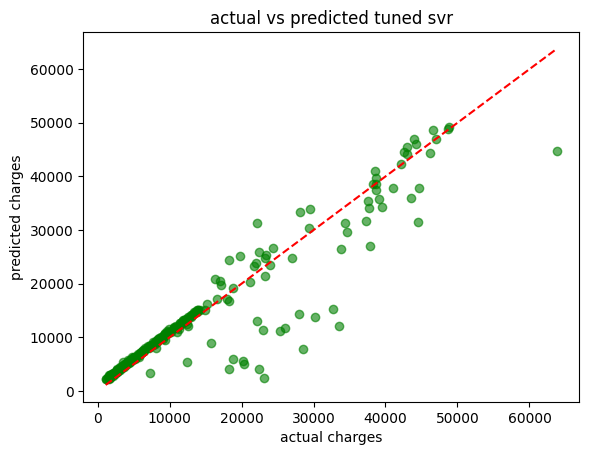

In [16]:
# compare tble
results = pd.DataFrame([res_lin, res_svr_base, res_svr_tuned]).round(4)
print(results)

plt.scatter(y_test, y_pred_svr, alpha=0.6, color="green")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("actual charges"); plt.ylabel("predicted charges")
plt.title("actual vs predicted tuned svr")